In [18]:
import pandas as pd
path = "https://raw.githubusercontent.com/ulka29/paper/7aad80ab3fe4ad5ffeabffb7c30bcb70edb218bd/01_data/processed/df_cleaned.csv"# import Check dataset
df= pd.read_csv(path)
df.head()

,tweet_text,cyberbullying_type,clean_tweet,lemmatized_tweet,sentiment_scores,negative,positive,neutral,compound
0,"in other words #katandandre, your food was cra...",not_cyberbullying,words katandandre food crapilicious mkr,word katandandre food crapilicious mkr,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...",0.000,0.000,1.000,0.0000
1,why is #aussietv so white? #mkr #theblock #ima...,not_cyberbullying,aussietv white mkr theblock imacelebrityau tod...,aussietv white mkr theblock imacelebrityau tod...,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...",0.000,0.000,1.000,0.0000
2,@xochitlsuckkks a classy whore? or more red ve...,not_cyberbullying,classy whore red velvet cupcakes,classy whore red velvet cupcake,"{'neg': 0.32, 'neu': 0.481, 'pos': 0.199, 'com...",0.320,0.199,0.481,-0.4137
3,"@jason_gio meh. :p thanks for the heads up, b...",not_cyberbullying,meh p thanks heads concerned another angry dud...,meh p thanks head concerned another angry dude...,"{'neg': 0.243, 'neu': 0.607, 'pos': 0.15, 'com...",0.243,0.150,0.607,-0.4854
4,@rudhoeenglish this is an isis account pretend...,not_cyberbullying,isis account pretending kurdish account like i...,isi account pretending kurdish account like is...,"{'neg': 0.129, 'neu': 0.691, 'pos': 0.18, 'com...",0.129,0.180,0.691,0.0258


In [19]:
# Select relevant features for SA + ML
df_ml = df[
    [
        'lemmatized_tweet',
        'negative',
        'positive',
        'neutral',
        'compound',
        'cyberbullying_type'
    ]
].copy()

# Check shape
print("\n:-------------Shape::-------------", df_ml.shape)

# Check column names
print("\n:-------------Columns::-------------")
print(df_ml.columns.tolist())

# Check missing values
print("\n----------------Missing values:-------------")
print(df_ml.isnull().sum())

# Display first 5 rows
df_ml.head()


:-------------Shape::------------- (42645, 6)

:-------------Columns::-------------
['lemmatized_tweet', 'negative', 'positive', 'neutral', 'compound', 'cyberbullying_type']

----------------Missing values:-------------
lemmatized_tweet      30
negative               0
positive               0
neutral                0
compound               0
cyberbullying_type     0
dtype: int64


,lemmatized_tweet,negative,positive,neutral,compound,cyberbullying_type
0,word katandandre food crapilicious mkr,0.000,0.000,1.000,0.0000,not_cyberbullying
1,aussietv white mkr theblock imacelebrityau tod...,0.000,0.000,1.000,0.0000,not_cyberbullying
2,classy whore red velvet cupcake,0.320,0.199,0.481,-0.4137,not_cyberbullying
3,meh p thanks head concerned another angry dude...,0.243,0.150,0.607,-0.4854,not_cyberbullying
4,isi account pretending kurdish account like is...,0.129,0.180,0.691,0.0258,not_cyberbullying


Classes:
['age' 'ethnicity' 'gender' 'not_cyberbullying' 'other_cyberbullying'
 'religion']

Label Mapping:
0 → age
1 → ethnicity
2 → gender
3 → not_cyberbullying
4 → other_cyberbullying
5 → religion

Train-Test Split
-------------------------
Training samples: 29851
Testing samples : 12794

TF-IDF Features
-------------------------
X_train TF-IDF: (29851, 10000)
X_test TF-IDF : (12794, 10000)

Combined Features
-------------------------
X_train: (29851, 10004)
X_test : (12794, 10004)

Class Distribution BEFORE SMOTE
--------------------------------
age                       : 5570
ethnicity                 : 5199
gender                    : 5243
not_cyberbullying         : 4511
other_cyberbullying       : 3753
religion                  : 5575

Class Distribution AFTER SMOTE
-------------------------------
age                       : 5575
ethnicity                 : 5575
gender                    : 5575
not_cyberbullying         : 5575
other_cyberbullying       : 5575
religion         

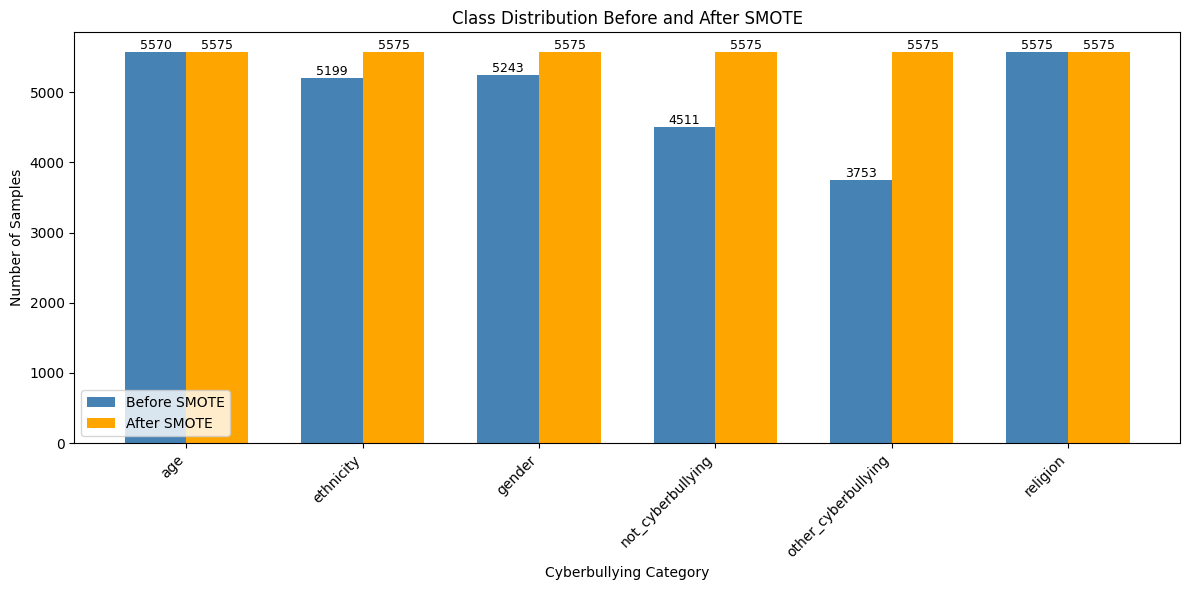

In [20]:
# ============================================================
# CELL 1: DATA PREPARATION
# TF-IDF + SENTIMENT ANALYSIS + SMOTE
# ============================================================

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from imblearn.over_sampling import SMOTE
from scipy.sparse import hstack
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. TEXT, SENTIMENT FEATURES AND TARGET
# ------------------------------------------------------------

X_text = df['lemmatized_tweet'].fillna('')
# Sentiment Analysis features
sentiment_features = [
    'negative',
    'positive',
    'neutral',
    'compound'
]

X_sentiment = df[sentiment_features].fillna(0)

# Target variable
y = df['cyberbullying_type']

# ------------------------------------------------------------
# 2. LABEL ENCODING
# ------------------------------------------------------------

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Classes:")
print(label_encoder.classes_)

# Label mapping
label_mapping = dict(
    enumerate(label_encoder.classes_)
)

print("\nLabel Mapping:")

for number, category in label_mapping.items():
    print(f"{number} → {category}")

# ------------------------------------------------------------
# 3. TRAIN-TEST SPLIT
# ------------------------------------------------------------

X_text_train, X_text_test, X_sent_train, X_sent_test, y_train, y_test = train_test_split(
    X_text,
    X_sentiment,
    y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)

print("\nTrain-Test Split")
print("-------------------------")
print("Training samples:", len(X_text_train))
print("Testing samples :", len(X_text_test))

# ------------------------------------------------------------
# 4. TF-IDF VECTORIZATION
# ------------------------------------------------------------

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_text_train)
X_test_tfidf = tfidf.transform(X_text_test)

print("\nTF-IDF Features")
print("-------------------------")
print("X_train TF-IDF:", X_train_tfidf.shape)
print("X_test TF-IDF :", X_test_tfidf.shape)

# ------------------------------------------------------------
# 5. COMBINE TF-IDF + SENTIMENT FEATURES
# ------------------------------------------------------------

X_train_combined = hstack([
    X_train_tfidf,
    X_sent_train.values
])

X_test_combined = hstack([
    X_test_tfidf,
    X_sent_test.values
])

print("\nCombined Features")
print("-------------------------")
print("X_train:", X_train_combined.shape)
print("X_test :", X_test_combined.shape)

# ------------------------------------------------------------
# 6. CLASS DISTRIBUTION BEFORE SMOTE
# ------------------------------------------------------------

print("\nClass Distribution BEFORE SMOTE")
print("--------------------------------")

before_smote = Counter(y_train)

for class_id, count in sorted(before_smote.items()):
    print(
        f"{label_encoder.classes_[class_id]:<25} : {count}"
    )

# ------------------------------------------------------------
# 7. SMOTE
# ------------------------------------------------------------

smote = SMOTE(
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_combined,
    y_train
)

# ------------------------------------------------------------
# 8. CLASS DISTRIBUTION AFTER SMOTE
# ------------------------------------------------------------

print("\nClass Distribution AFTER SMOTE")
print("-------------------------------")

after_smote = Counter(y_train_smote)

for class_id, count in sorted(after_smote.items()):
    print(
        f"{label_encoder.classes_[class_id]:<25} : {count}"
    )

print("\nAfter SMOTE")
print("-------------------------")
print("X_train:", X_train_smote.shape)
print("y_train:", y_train_smote.shape)

# ------------------------------------------------------------
# 9. CATEGORY-WISE COMPARISON
# ------------------------------------------------------------

categories = label_encoder.classes_

before_counts = [
    before_smote[i]
    for i in range(len(categories))
]

after_counts = [
    after_smote[i]
    for i in range(len(categories))
]



# ------------------------------------------------------------
# 10. BAR CHART
# ------------------------------------------------------------

x = np.arange(len(categories))
width = 0.35

plt.figure(figsize=(12, 6))

bars1 = plt.bar(
    x - width / 2,
    before_counts,
    width,
    label='Before SMOTE',
    color='steelblue'
)

bars2 = plt.bar(
    x + width / 2,
    after_counts,
    width,
    label='After SMOTE',
    color='orange'
)

plt.xlabel('Cyberbullying Category')
plt.ylabel('Number of Samples')
plt.title('Class Distribution Before and After SMOTE')

plt.xticks(
    x,
    categories,
    rotation=45,
    ha='right'
)

plt.legend()

# Add values on bars
for bars in [bars1, bars2]:

    for bar in bars:

        height = bar.get_height()

        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            str(int(height)),
            ha='center',
            va='bottom',
            fontsize=9
        )

plt.tight_layout()
plt.show()

## Balancing strategy
### TF-IDF + SA + LOGISTIC REGRESSION

### No Balancing

In [21]:

# ============================================================
# WORD TF-IDF + SENTIMENT ANALYSIS
# NO BALANCING + LOGISTIC REGRESSION + EVALUATION
# FIXED HYPERPARAMETER: C = 1
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# ------------------------------------------------------------
# 1. LOGISTIC REGRESSION WITH FIXED HYPERPARAMETERS
# ------------------------------------------------------------

lr_none = LogisticRegression(
    C=1,
    max_iter=1000,
    random_state=42
)

# ------------------------------------------------------------
# 2. TRAIN ON ORIGINAL DATA
# ------------------------------------------------------------

print("Training SA + No Balancing + Logistic Regression...")
print("Fixed hyperparameters: C=1, max_iter=1000, random_state=42")

lr_none.fit(
    X_train_combined,
    y_train
)

# ------------------------------------------------------------
# 3. TRAINED MODEL
# ------------------------------------------------------------

best_none = lr_none

# ------------------------------------------------------------
# 4. PREDICTION
# ------------------------------------------------------------

y_pred_none = best_none.predict(
    X_test_combined
)

# ------------------------------------------------------------
# 5. EVALUATION
# ------------------------------------------------------------

none_accuracy = accuracy_score(
    y_test,
    y_pred_none
)

none_weighted_f1 = f1_score(
    y_test,
    y_pred_none,
    average='weighted'
)

none_macro_f1 = f1_score(
    y_test,
    y_pred_none,
    average='macro'
)

# ------------------------------------------------------------
# 6. RESULTS
# ------------------------------------------------------------

print("\n==============================================")
print("NO BALANCING + LOGISTIC REGRESSION")
print("==============================================")

print(f"Accuracy     : {none_accuracy:.4f}")
print(f"Weighted F1  : {none_weighted_f1:.4f}")
print(f"Macro F1     : {none_macro_f1:.4f}")

# ------------------------------------------------------------
# 7. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nClassification Report")
print("-------------------------")

print(
    classification_report(
        y_test,
        y_pred_none,
        labels=range(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)


Training SA + No Balancing + Logistic Regression...
Fixed hyperparameters: C=1, max_iter=1000, random_state=42

NO BALANCING + LOGISTIC REGRESSION
Accuracy     : 0.8493
Weighted F1  : 0.8503
Macro F1     : 0.8304

Classification Report
-------------------------
                     precision    recall  f1-score   support

                age       0.95      0.97      0.96      2387
          ethnicity       0.97      0.98      0.98      2228
             gender       0.92      0.85      0.88      2248
  not_cyberbullying       0.60      0.63      0.61      1934
other_cyberbullying       0.59      0.59      0.59      1608
           religion       0.95      0.95      0.95      2389

           accuracy                           0.85     12794
          macro avg       0.83      0.83      0.83     12794
       weighted avg       0.85      0.85      0.85     12794



### Class Weight

In [22]:

# ============================================================
# WORD TF-IDF + SENTIMENT ANALYSIS
# CLASS WEIGHT + LOGISTIC REGRESSION + EVALUATION
# FIXED HYPERPARAMETER: C = 1
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. LOGISTIC REGRESSION WITH CLASS WEIGHT
# ------------------------------------------------------------

lr_weight = LogisticRegression(
    C=1,
    max_iter=1000,
    random_state=42,
    class_weight='balanced'
)

# ------------------------------------------------------------
# 2. TRAIN ON ORIGINAL DATA
# ------------------------------------------------------------

print("Training SA + Class Weight + Logistic Regression...")
print("Fixed hyperparameters: C=1, max_iter=1000, random_state=42")
print("Class weight: balanced")

lr_weight.fit(
    X_train_combined,
    y_train
)

# ------------------------------------------------------------
# 3. TRAINED MODEL
# ------------------------------------------------------------

best_weight = lr_weight

# ------------------------------------------------------------
# 4. PREDICTION ON ORIGINAL TEST DATA
# ------------------------------------------------------------

y_pred_weight = best_weight.predict(
    X_test_combined
)

# ------------------------------------------------------------
# 5. EVALUATION
# ------------------------------------------------------------

weight_accuracy = accuracy_score(
    y_test,
    y_pred_weight
)

weight_weighted_f1 = f1_score(
    y_test,
    y_pred_weight,
    average='weighted'
)

weight_macro_f1 = f1_score(
    y_test,
    y_pred_weight,
    average='macro'
)

# ------------------------------------------------------------
# 6. RESULTS
# ------------------------------------------------------------

print("\n==============================================")
print("CLASS WEIGHT + LOGISTIC REGRESSION")
print("==============================================")

print(f"Accuracy     : {weight_accuracy:.4f}")
print(f"Weighted F1  : {weight_weighted_f1:.4f}")
print(f"Macro F1     : {weight_macro_f1:.4f}")

# ------------------------------------------------------------
# 7. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nClassification Report")
print("-------------------------")

print(
    classification_report(
        y_test,
        y_pred_weight,
        labels=range(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)


Training SA + Class Weight + Logistic Regression...
Fixed hyperparameters: C=1, max_iter=1000, random_state=42
Class weight: balanced

CLASS WEIGHT + LOGISTIC REGRESSION
Accuracy     : 0.8478
Weighted F1  : 0.8506
Macro F1     : 0.8314

Classification Report
-------------------------
                     precision    recall  f1-score   support

                age       0.96      0.96      0.96      2387
          ethnicity       0.98      0.98      0.98      2228
             gender       0.93      0.84      0.88      2248
  not_cyberbullying       0.60      0.60      0.60      1934
other_cyberbullying       0.57      0.66      0.61      1608
           religion       0.96      0.94      0.95      2389

           accuracy                           0.85     12794
          macro avg       0.83      0.83      0.83     12794
       weighted avg       0.86      0.85      0.85     12794



### Smote

In [23]:

# ============================================================
# WORD TF-IDF + SENTIMENT ANALYSIS
# SMOTE + LOGISTIC REGRESSION + EVALUATION
# FIXED HYPERPARAMETER: C = 1
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# ------------------------------------------------------------
# 1. LOGISTIC REGRESSION WITH FIXED HYPERPARAMETERS
# ------------------------------------------------------------

lr_smote = LogisticRegression(
    C=1,
    max_iter=1000,
    random_state=42
)

# ------------------------------------------------------------
# 2. TRAIN ON SMOTE-RESAMPLED TRAINING DATA
# ------------------------------------------------------------

print("Training SA + SMOTE + Logistic Regression...")
print("Fixed hyperparameters: C=1, max_iter=1000, random_state=42")

lr_smote.fit(
    X_train_smote,
    y_train_smote
)

# ------------------------------------------------------------
# 3. TRAINED MODEL
# ------------------------------------------------------------

best_smote = lr_smote

# ------------------------------------------------------------
# 4. PREDICTION ON ORIGINAL TEST DATA
# ------------------------------------------------------------

y_pred_smote = best_smote.predict(
    X_test_combined
)

# ------------------------------------------------------------
# 5. EVALUATION
# ------------------------------------------------------------

smote_accuracy = accuracy_score(
    y_test,
    y_pred_smote
)

smote_weighted_f1 = f1_score(
    y_test,
    y_pred_smote,
    average='weighted'
)

smote_macro_f1 = f1_score(
    y_test,
    y_pred_smote,
    average='macro'
)

# ------------------------------------------------------------
# 6. RESULTS
# ------------------------------------------------------------

print("\n==============================================")
print("SMOTE + LOGISTIC REGRESSION")
print("==============================================")

print(f"Accuracy     : {smote_accuracy:.4f}")
print(f"Weighted F1  : {smote_weighted_f1:.4f}")
print(f"Macro F1     : {smote_macro_f1:.4f}")

# ------------------------------------------------------------
# 7. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nClassification Report")
print("-------------------------")

print(
    classification_report(
        y_test,
        y_pred_smote,
        labels=range(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)


Training SA + SMOTE + Logistic Regression...
Fixed hyperparameters: C=1, max_iter=1000, random_state=42

SMOTE + LOGISTIC REGRESSION
Accuracy     : 0.8459
Weighted F1  : 0.8482
Macro F1     : 0.8285

Classification Report
-------------------------
                     precision    recall  f1-score   support

                age       0.95      0.97      0.96      2387
          ethnicity       0.98      0.98      0.98      2228
             gender       0.93      0.84      0.88      2248
  not_cyberbullying       0.60      0.58      0.59      1934
other_cyberbullying       0.56      0.65      0.60      1608
           religion       0.96      0.95      0.95      2389

           accuracy                           0.85     12794
          macro avg       0.83      0.83      0.83     12794
       weighted avg       0.85      0.85      0.85     12794



## TF-IDF + SA + Linear SVM

### No balance

In [24]:
# ============================================================
# WORD TF-IDF + SENTIMENT ANALYSIS
# NO BALANCING + LINEAR SVM + EVALUATION
# FIXED HYPERPARAMETER: C = 1
# ============================================================

from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# ------------------------------------------------------------
# 1. LINEAR SVM WITHOUT CLASS WEIGHT
# ------------------------------------------------------------

svm_none = LinearSVC(
    C=1,
    max_iter=1000,
    random_state=42
)

# ------------------------------------------------------------
# 2. TRAIN ON ORIGINAL DATA
# ------------------------------------------------------------

print("Training SA + No Balancing + Linear SVM...")
print("Fixed hyperparameters: C=1, max_iter=1000, random_state=42")
print("Balancing: None")

svm_none.fit(
    X_train_combined,
    y_train
)

# ------------------------------------------------------------
# 3. TRAINED MODEL
# ------------------------------------------------------------

best_svm_none = svm_none

# ------------------------------------------------------------
# 4. PREDICTION ON ORIGINAL TEST DATA
# ------------------------------------------------------------

y_pred_svm_none = best_svm_none.predict(
    X_test_combined
)

# ------------------------------------------------------------
# 5. EVALUATION
# ------------------------------------------------------------

svm_none_accuracy = accuracy_score(
    y_test,
    y_pred_svm_none
)

svm_none_weighted_f1 = f1_score(
    y_test,
    y_pred_svm_none,
    average='weighted'
)

svm_none_macro_f1 = f1_score(
    y_test,
    y_pred_svm_none,
    average='macro'
)

# ------------------------------------------------------------
# 6. RESULTS
# ------------------------------------------------------------

print("\n==============================================")
print("NO BALANCING + LINEAR SVM")
print("==============================================")

print(f"Accuracy     : {svm_none_accuracy:.4f}")
print(f"Weighted F1  : {svm_none_weighted_f1:.4f}")
print(f"Macro F1     : {svm_none_macro_f1:.4f}")

# ------------------------------------------------------------
# 7. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nClassification Report")
print("-------------------------")

print(
    classification_report(
        y_test,
        y_pred_svm_none,
        labels=list(range(len(label_encoder.classes_))),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

Training SA + No Balancing + Linear SVM...
Fixed hyperparameters: C=1, max_iter=1000, random_state=42
Balancing: None

NO BALANCING + LINEAR SVM
Accuracy     : 0.8433
Weighted F1  : 0.8433
Macro F1     : 0.8226

Classification Report
-------------------------
                     precision    recall  f1-score   support

                age       0.95      0.97      0.96      2387
          ethnicity       0.97      0.98      0.98      2228
             gender       0.90      0.86      0.88      2248
  not_cyberbullying       0.59      0.59      0.59      1934
other_cyberbullying       0.57      0.58      0.58      1608
           religion       0.95      0.95      0.95      2389

           accuracy                           0.84     12794
          macro avg       0.82      0.82      0.82     12794
       weighted avg       0.84      0.84      0.84     12794



### Class Weight

In [25]:
# ============================================================
# WORD TF-IDF + SENTIMENT ANALYSIS
# CLASS WEIGHT + LINEAR SVM + EVALUATION
# FIXED HYPERPARAMETER: C = 1
# ============================================================

from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# ------------------------------------------------------------
# 1. LINEAR SVM WITH CLASS WEIGHT
# ------------------------------------------------------------

svm_weight = LinearSVC(
    C=1,
    max_iter=1000,
    random_state=42,
    class_weight='balanced'
)

# ------------------------------------------------------------
# 2. TRAIN ON ORIGINAL DATA
# ------------------------------------------------------------

print("Training SA + Class Weight + Linear SVM...")
print("Fixed hyperparameters: C=1, max_iter=1000, random_state=42")
print("Class weight: balanced")

svm_weight.fit(
    X_train_combined,
    y_train
)

# ------------------------------------------------------------
# 3. TRAINED MODEL
# ------------------------------------------------------------

best_svm_weight = svm_weight

# ------------------------------------------------------------
# 4. PREDICTION ON ORIGINAL TEST DATA
# ------------------------------------------------------------

y_pred_svm_weight = best_svm_weight.predict(
    X_test_combined
)

# ------------------------------------------------------------
# 5. EVALUATION
# ------------------------------------------------------------

svm_weight_accuracy = accuracy_score(
    y_test,
    y_pred_svm_weight
)

svm_weight_weighted_f1 = f1_score(
    y_test,
    y_pred_svm_weight,
    average='weighted'
)

svm_weight_macro_f1 = f1_score(
    y_test,
    y_pred_svm_weight,
    average='macro'
)

# ------------------------------------------------------------
# 6. RESULTS
# ------------------------------------------------------------

print("\n==============================================")
print("CLASS WEIGHT + LINEAR SVM")
print("==============================================")

print(f"Accuracy     : {svm_weight_accuracy:.4f}")
print(f"Weighted F1  : {svm_weight_weighted_f1:.4f}")
print(f"Macro F1     : {svm_weight_macro_f1:.4f}")

# ------------------------------------------------------------
# 7. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nClassification Report")
print("-------------------------")

print(
    classification_report(
        y_test,
        y_pred_svm_weight,
        labels=list(range(len(label_encoder.classes_))),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)


Training SA + Class Weight + Linear SVM...
Fixed hyperparameters: C=1, max_iter=1000, random_state=42
Class weight: balanced

CLASS WEIGHT + LINEAR SVM
Accuracy     : 0.8421
Weighted F1  : 0.8429
Macro F1     : 0.8223

Classification Report
-------------------------
                     precision    recall  f1-score   support

                age       0.95      0.96      0.96      2387
          ethnicity       0.97      0.98      0.98      2228
             gender       0.91      0.85      0.88      2248
  not_cyberbullying       0.59      0.59      0.59      1934
other_cyberbullying       0.56      0.60      0.58      1608
           religion       0.95      0.95      0.95      2389

           accuracy                           0.84     12794
          macro avg       0.82      0.82      0.82     12794
       weighted avg       0.84      0.84      0.84     12794



### SMOTE

In [26]:
# ============================================================
# WORD TF-IDF + SENTIMENT ANALYSIS
# SMOTE + LINEAR SVM + EVALUATION
# ============================================================

from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

svm_smote = LinearSVC(
    C=1,
    max_iter=1000,
    random_state=42
)

print("Training SA + SMOTE + Linear SVM...")

svm_smote.fit(
    X_train_smote,
    y_train_smote
)

best_svm_smote = svm_smote

y_pred_svm_smote = best_svm_smote.predict(
    X_test_combined
)

svm_smote_accuracy = accuracy_score(
    y_test,
    y_pred_svm_smote
)

svm_smote_weighted_f1 = f1_score(
    y_test,
    y_pred_svm_smote,
    average='weighted'
)

svm_smote_macro_f1 = f1_score(
    y_test,
    y_pred_svm_smote,
    average='macro'
)

print("\n==============================================")
print("SMOTE + LINEAR SVM")
print("==============================================")

print(f"Accuracy     : {svm_smote_accuracy:.4f}")
print(f"Weighted F1  : {svm_smote_weighted_f1:.4f}")
print(f"Macro F1     : {svm_smote_macro_f1:.4f}")

print("\nClassification Report")
print("-------------------------")

print(
    classification_report(
        y_test,
        y_pred_svm_smote,
        labels=list(range(len(label_encoder.classes_))),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

Training SA + SMOTE + Linear SVM...

SMOTE + LINEAR SVM
Accuracy     : 0.8384
Weighted F1  : 0.8390
Macro F1     : 0.8181

Classification Report
-------------------------
                     precision    recall  f1-score   support

                age       0.95      0.96      0.96      2387
          ethnicity       0.97      0.98      0.98      2228
             gender       0.90      0.85      0.88      2248
  not_cyberbullying       0.59      0.56      0.57      1934
other_cyberbullying       0.55      0.60      0.58      1608
           religion       0.96      0.95      0.95      2389

           accuracy                           0.84     12794
          macro avg       0.82      0.82      0.82     12794
       weighted avg       0.84      0.84      0.84     12794



## Feature-space size and n-grams Testing
### Logistic Regression + No balance + TFIDF + sentiment

### TF-IDF VECTORIZATION (15000), ngram_range=(1, 2)

In [27]:

# ------------------------------------------------------------
# TF-IDF VECTORIZATION (15000)
# ------------------------------------------------------------

tfidf = TfidfVectorizer(
    max_features=15000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_text_train)
X_test_tfidf = tfidf.transform(X_text_test)

print("\nTF-IDF Features")
print("-------------------------")
print("X_train TF-IDF:", X_train_tfidf.shape)
print("X_test TF-IDF :", X_test_tfidf.shape)

# ------------------------------------------------------------
# COMBINE TF-IDF + SENTIMENT FEATURES
# ------------------------------------------------------------

X_train_combined = hstack([
    X_train_tfidf,
    X_sent_train.values
])

X_test_combined = hstack([
    X_test_tfidf,
    X_sent_test.values
])

print("\nCombined Features")
print("-------------------------")
print("X_train:", X_train_combined.shape)
print("X_test :", X_test_combined.shape)



TF-IDF Features
-------------------------
X_train TF-IDF: (29851, 15000)
X_test TF-IDF : (12794, 15000)

Combined Features
-------------------------
X_train: (29851, 15004)
X_test : (12794, 15004)


In [28]:
# ============================================================
# NO BALANCING + LOGISTIC REGRESSION + EVALUATION
# FIXED HYPERPARAMETERS: C = 1, max_iter = 1000
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# ------------------------------------------------------------
# 1. LOGISTIC REGRESSION WITHOUT CLASS WEIGHTS
# ------------------------------------------------------------

lr_none = LogisticRegression(
    C=1,
    max_iter=1000,
    random_state=42
)

# ------------------------------------------------------------
# 2. TRAIN ON ORIGINAL DATA
# ------------------------------------------------------------

print("Training SA + No Balancing + Logistic Regression...")
print("Fixed hyperparameters: C=1, max_iter=1000, random_state=42")
print("Balancing: None")

lr_none.fit(
    X_train_combined,
    y_train
)

# ------------------------------------------------------------
# 3. TRAINED MODEL
# ------------------------------------------------------------

best_lr_none = lr_none

# ------------------------------------------------------------
# 4. PREDICTION
# ------------------------------------------------------------

y_pred_lr_none = best_lr_none.predict(
    X_test_combined
)

# ------------------------------------------------------------
# 5. EVALUATION
# ------------------------------------------------------------

lr_none_accuracy = accuracy_score(
    y_test,
    y_pred_lr_none
)

lr_none_weighted_f1 = f1_score(
    y_test,
    y_pred_lr_none,
    average='weighted'
)

lr_none_macro_f1 = f1_score(
    y_test,
    y_pred_lr_none,
    average='macro'
)

# ------------------------------------------------------------
# 6. RESULTS
# ------------------------------------------------------------

print("\n==============================================")
print("NO BALANCING + LOGISTIC REGRESSION")
print("==============================================")

print(f"Accuracy     : {lr_none_accuracy:.4f}")
print(f"Weighted F1  : {lr_none_weighted_f1:.4f}")
print(f"Macro F1     : {lr_none_macro_f1:.4f}")

# ------------------------------------------------------------
# 7. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nClassification Report")
print("-------------------------")

print(
    classification_report(
        y_test,
        y_pred_lr_none,
        labels=list(range(len(label_encoder.classes_))),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

Training SA + No Balancing + Logistic Regression...
Fixed hyperparameters: C=1, max_iter=1000, random_state=42
Balancing: None

NO BALANCING + LOGISTIC REGRESSION
Accuracy     : 0.8487
Weighted F1  : 0.8495
Macro F1     : 0.8297

Classification Report
-------------------------
                     precision    recall  f1-score   support

                age       0.95      0.97      0.96      2387
          ethnicity       0.97      0.98      0.98      2228
             gender       0.92      0.85      0.88      2248
  not_cyberbullying       0.60      0.63      0.61      1934
other_cyberbullying       0.59      0.59      0.59      1608
           religion       0.95      0.95      0.95      2389

           accuracy                           0.85     12794
          macro avg       0.83      0.83      0.83     12794
       weighted avg       0.85      0.85      0.85     12794



### TF-IDF VECTORIZATION (20000) and ngram_range=(1, 2)

In [29]:

# ------------------------------------------------------------
# TF-IDF VECTORIZATION (20000)
# ------------------------------------------------------------

tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_text_train)
X_test_tfidf = tfidf.transform(X_text_test)

print("\nTF-IDF Features")
print("-------------------------")
print("X_train TF-IDF:", X_train_tfidf.shape)
print("X_test TF-IDF :", X_test_tfidf.shape)

# ------------------------------------------------------------
# COMBINE TF-IDF + SENTIMENT FEATURES
# ------------------------------------------------------------

X_train_combined = hstack([
    X_train_tfidf,
    X_sent_train.values
])

X_test_combined = hstack([
    X_test_tfidf,
    X_sent_test.values
])

print("\nCombined Features")
print("-------------------------")
print("X_train:", X_train_combined.shape)
print("X_test :", X_test_combined.shape)



TF-IDF Features
-------------------------
X_train TF-IDF: (29851, 20000)
X_test TF-IDF : (12794, 20000)

Combined Features
-------------------------
X_train: (29851, 20004)
X_test : (12794, 20004)


In [30]:
# ============================================================
# WORD TF-IDF + SENTIMENT ANALYSIS
# NO BALANCING + LOGISTIC REGRESSION + EVALUATION
# FIXED HYPERPARAMETERS: C = 1, max_iter = 1000
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# ------------------------------------------------------------
# 1. LOGISTIC REGRESSION WITHOUT CLASS WEIGHTS
# ------------------------------------------------------------

lr_none = LogisticRegression(
    C=1,
    max_iter=1000,
    random_state=42
)

# ------------------------------------------------------------
# 2. TRAIN ON ORIGINAL DATA WITHOUT BALANCING
# ------------------------------------------------------------

print(
    "Training TF-IDF (20000, n-gram 1-2) + Sentiment "
    "+ No Balancing + Logistic Regression..."
)

print("Fixed hyperparameters: C=1, max_iter=1000, random_state=42")
print("Balancing: None")

lr_none.fit(
    X_train_combined,
    y_train
)

# ------------------------------------------------------------
# 3. TRAINED MODEL
# ------------------------------------------------------------

best_lr_none = lr_none

# ------------------------------------------------------------
# 4. PREDICTION ON TEST DATA
# ------------------------------------------------------------

y_pred_lr_none = best_lr_none.predict(
    X_test_combined
)

# ------------------------------------------------------------
# 5. EVALUATION
# ------------------------------------------------------------

lr_none_accuracy = accuracy_score(
    y_test,
    y_pred_lr_none
)

lr_none_weighted_f1 = f1_score(
    y_test,
    y_pred_lr_none,
    average='weighted'
)

lr_none_macro_f1 = f1_score(
    y_test,
    y_pred_lr_none,
    average='macro'
)

# ------------------------------------------------------------
# 6. RESULTS
# ------------------------------------------------------------

print("\n==============================================")
print("TF-IDF (20000, N-GRAM 1-2) + SENTIMENT")
print("NO BALANCING + LOGISTIC REGRESSION")
print("==============================================")

print(f"Accuracy     : {lr_none_accuracy:.4f}")
print(f"Weighted F1  : {lr_none_weighted_f1:.4f}")
print(f"Macro F1     : {lr_none_macro_f1:.4f}")

# ------------------------------------------------------------
# 7. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nClassification Report")
print("-------------------------")

print(
    classification_report(
        y_test,
        y_pred_lr_none,
        labels=list(range(len(label_encoder.classes_))),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

Training TF-IDF (20000, n-gram 1-2) + Sentiment + No Balancing + Logistic Regression...
Fixed hyperparameters: C=1, max_iter=1000, random_state=42
Balancing: None

TF-IDF (20000, N-GRAM 1-2) + SENTIMENT
NO BALANCING + LOGISTIC REGRESSION
Accuracy     : 0.8505
Weighted F1  : 0.8511
Macro F1     : 0.8315

Classification Report
-------------------------
                     precision    recall  f1-score   support

                age       0.95      0.97      0.96      2387
          ethnicity       0.97      0.98      0.98      2228
             gender       0.92      0.85      0.89      2248
  not_cyberbullying       0.60      0.63      0.62      1934
other_cyberbullying       0.60      0.59      0.59      1608
           religion       0.95      0.95      0.95      2389

           accuracy                           0.85     12794
          macro avg       0.83      0.83      0.83     12794
       weighted avg       0.85      0.85      0.85     12794



### TF-IDF VECTORIZATION (20000), ngram_range=(1, 3)

In [31]:
# ------------------------------------------------------------
# TF-IDF VECTORIZATION (20000)
# ------------------------------------------------------------

tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 3)
)

X_train_tfidf = tfidf.fit_transform(X_text_train)
X_test_tfidf = tfidf.transform(X_text_test)

print("\nTF-IDF Features")
print("-------------------------")
print("X_train TF-IDF:", X_train_tfidf.shape)
print("X_test TF-IDF :", X_test_tfidf.shape)

# ------------------------------------------------------------
# COMBINE TF-IDF + SENTIMENT FEATURES
# ------------------------------------------------------------

X_train_combined = hstack([
    X_train_tfidf,
    X_sent_train.values
])

X_test_combined = hstack([
    X_test_tfidf,
    X_sent_test.values
])

print("\nCombined Features")
print("-------------------------")
print("X_train:", X_train_combined.shape)
print("X_test :", X_test_combined.shape)



TF-IDF Features
-------------------------
X_train TF-IDF: (29851, 20000)
X_test TF-IDF : (12794, 20000)

Combined Features
-------------------------
X_train: (29851, 20004)
X_test : (12794, 20004)


In [32]:
# ============================================================
# WORD TF-IDF + SENTIMENT ANALYSIS
# TF-IDF (20000, N-GRAM 1-3)
# NO BALANCING + LOGISTIC REGRESSION + EVALUATION
# FIXED HYPERPARAMETERS: C = 1, max_iter = 1000
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# ------------------------------------------------------------
# 1. LOGISTIC REGRESSION WITHOUT CLASS WEIGHTS
# ------------------------------------------------------------

lr_none = LogisticRegression(
    C=1,
    max_iter=1000,
    random_state=42
)

# ------------------------------------------------------------
# 2. TRAIN ON ORIGINAL DATA WITHOUT BALANCING
# ------------------------------------------------------------

print(
    "Training TF-IDF (20000, n-gram 1-3) + Sentiment "
    "+ No Balancing + Logistic Regression..."
)

print("Fixed hyperparameters: C=1, max_iter=1000, random_state=42")
print("Balancing: None")

lr_none.fit(
    X_train_combined,
    y_train
)

# ------------------------------------------------------------
# 3. TRAINED MODEL
# ------------------------------------------------------------

best_lr_none = lr_none

# ------------------------------------------------------------
# 4. PREDICTION ON TEST DATA
# ------------------------------------------------------------

y_pred_lr_none = best_lr_none.predict(
    X_test_combined
)

# ------------------------------------------------------------
# 5. EVALUATION
# ------------------------------------------------------------

lr_none_accuracy = accuracy_score(
    y_test,
    y_pred_lr_none
)

lr_none_weighted_f1 = f1_score(
    y_test,
    y_pred_lr_none,
    average='weighted'
)

lr_none_macro_f1 = f1_score(
    y_test,
    y_pred_lr_none,
    average='macro'
)

# ------------------------------------------------------------
# 6. RESULTS
# ------------------------------------------------------------

print("\n==============================================")
print("TF-IDF (20000, N-GRAM 1-3) + SENTIMENT")
print("NO BALANCING + LOGISTIC REGRESSION")
print("==============================================")

print(f"Accuracy     : {lr_none_accuracy:.4f}")
print(f"Weighted F1  : {lr_none_weighted_f1:.4f}")
print(f"Macro F1     : {lr_none_macro_f1:.4f}")

# ------------------------------------------------------------
# 7. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nClassification Report")
print("-------------------------")

print(
    classification_report(
        y_test,
        y_pred_lr_none,
        labels=list(range(len(label_encoder.classes_))),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

Training TF-IDF (20000, n-gram 1-3) + Sentiment + No Balancing + Logistic Regression...
Fixed hyperparameters: C=1, max_iter=1000, random_state=42
Balancing: None

TF-IDF (20000, N-GRAM 1-3) + SENTIMENT
NO BALANCING + LOGISTIC REGRESSION
Accuracy     : 0.8506
Weighted F1  : 0.8511
Macro F1     : 0.8316

Classification Report
-------------------------
                     precision    recall  f1-score   support

                age       0.95      0.97      0.96      2387
          ethnicity       0.97      0.98      0.98      2228
             gender       0.92      0.85      0.89      2248
  not_cyberbullying       0.60      0.63      0.62      1934
other_cyberbullying       0.60      0.59      0.60      1608
           religion       0.95      0.95      0.95      2389

           accuracy                           0.85     12794
          macro avg       0.83      0.83      0.83     12794
       weighted avg       0.85      0.85      0.85     12794



as accuracy does not improves much we will keep model simple for further experiments